In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [71]:
df = pd.read_csv('IPL_Matches_tail_300.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,date,season,city,venue,team1,team2,toss_winner,toss_decision,...,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players,winner_encoded
0,0,0,20-05-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Chennai Super Kings,Rajasthan Royals,Chennai Super Kings,bat,...,R Ashwin,M Nayyar,CB Gaffaney,NA Patwardhan,YC Barde,PG Pathak,20,"RD Gaikwad, DP Conway, MM Ali, N Jagadeesan, A...","YBK Jaiswal, JC Buttler, SV Samson, D Padikkal...",8
1,1,1,21-05-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Delhi Capitals,Mumbai Indians,Mumbai Indians,field,...,JJ Bumrah,J Srinath,Nitin Menon,Tapan Sharma,HAS Khalid,GR Sadashiv Iyer,20,"PP Shaw, DA Warner, MR Marsh, RR Pant, SN Khan...","Ishan Kishan, RG Sharma, D Brevis, Tilak Varma...",5
2,2,2,22-05-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,Punjab Kings,Sunrisers Hyderabad,bat,...,Harpreet Brar,J Srinath,AK Chaudhary,NA Patwardhan,CB Gaffaney,Navdeep Singh,20,"PK Garg, Abhishek Sharma, RA Tripathi, AK Mark...","JM Bairstow, S Dhawan, M Shahrukh Khan, MA Aga...",7
3,3,3,24-05-2022,2022,Kolkata,"Eden Gardens, Kolkata",Rajasthan Royals,Gujarat Titans,Gujarat Titans,field,...,DA Miller,M Nayyar,BNJ Oxenford,VK Sharma,MA Gough,J Madanagopal,20,"YBK Jaiswal, JC Buttler, SV Samson, D Padikkal...","WP Saha, Shubman Gill, MS Wade, HH Pandya, DA ...",2
4,4,4,25-05-2022,2022,Kolkata,"Eden Gardens, Kolkata",Royal Challengers Bengaluru,Lucknow Super Giants,Lucknow Super Giants,field,...,RM Patidar,M Nayyar,J Madanagopal,MA Gough,BNJ Oxenford,VK Sharma,20,"V Kohli, F du Plessis, RM Patidar, GJ Maxwell,...","Q de Kock, KL Rahul, M Vohra, DJ Hooda, MP Sto...",9


In [72]:
# checking shape of the dataframe

df.shape

(300, 28)

<Axes: xlabel='count', ylabel='toss_winner'>

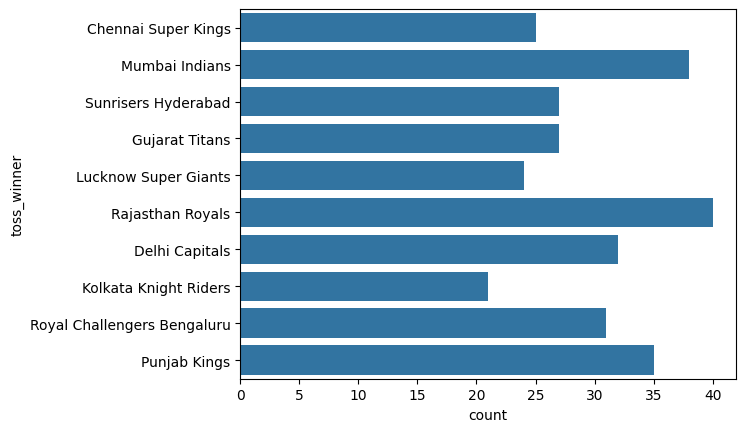

In [73]:
# toss winner distribution
# shows which teams won most tosses

sns.countplot(
    df['toss_winner']
)

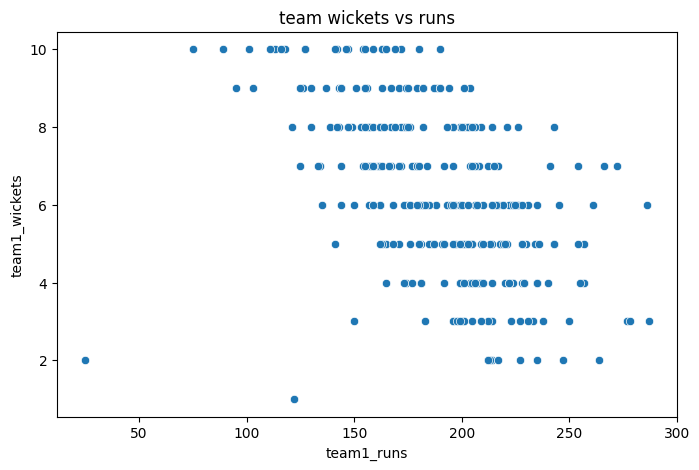

In [74]:
# team1 wickets vs team1 runs

plt.figure(figsize=(8,5))
sns.scatterplot(
    y = 'team1_wickets' ,
    x = 'team1_runs' ,
    data = df
)
plt.title("team wickets vs runs")
plt.show()

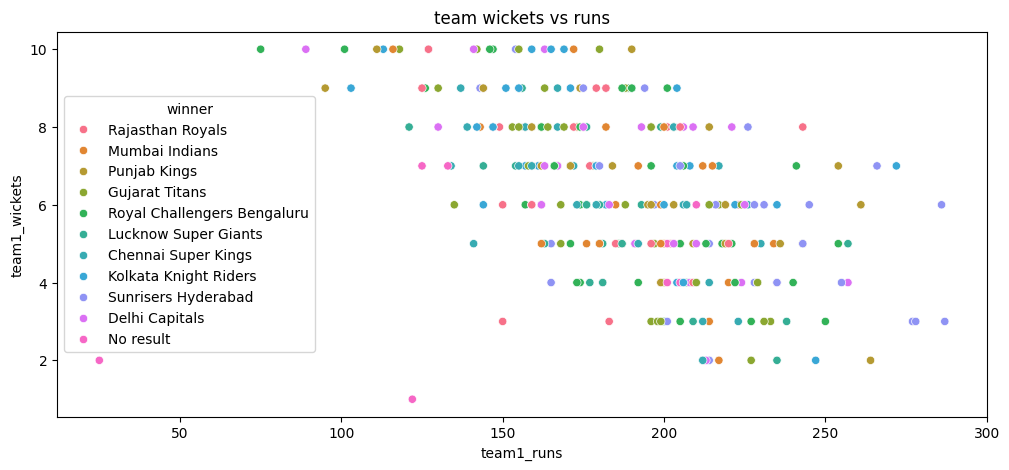

In [75]:
# team1 wickets vs team1 runs with winner

plt.figure(figsize=(12,5))
sns.scatterplot(
    x = 'team1_runs' ,
    y = 'team1_wickets',
    data = df ,
    hue = 'winner'
).tick_params(axis = 'x' , rotation = 0)
plt.title("team wickets vs runs")
plt.show()

<Figure size 800x600 with 0 Axes>

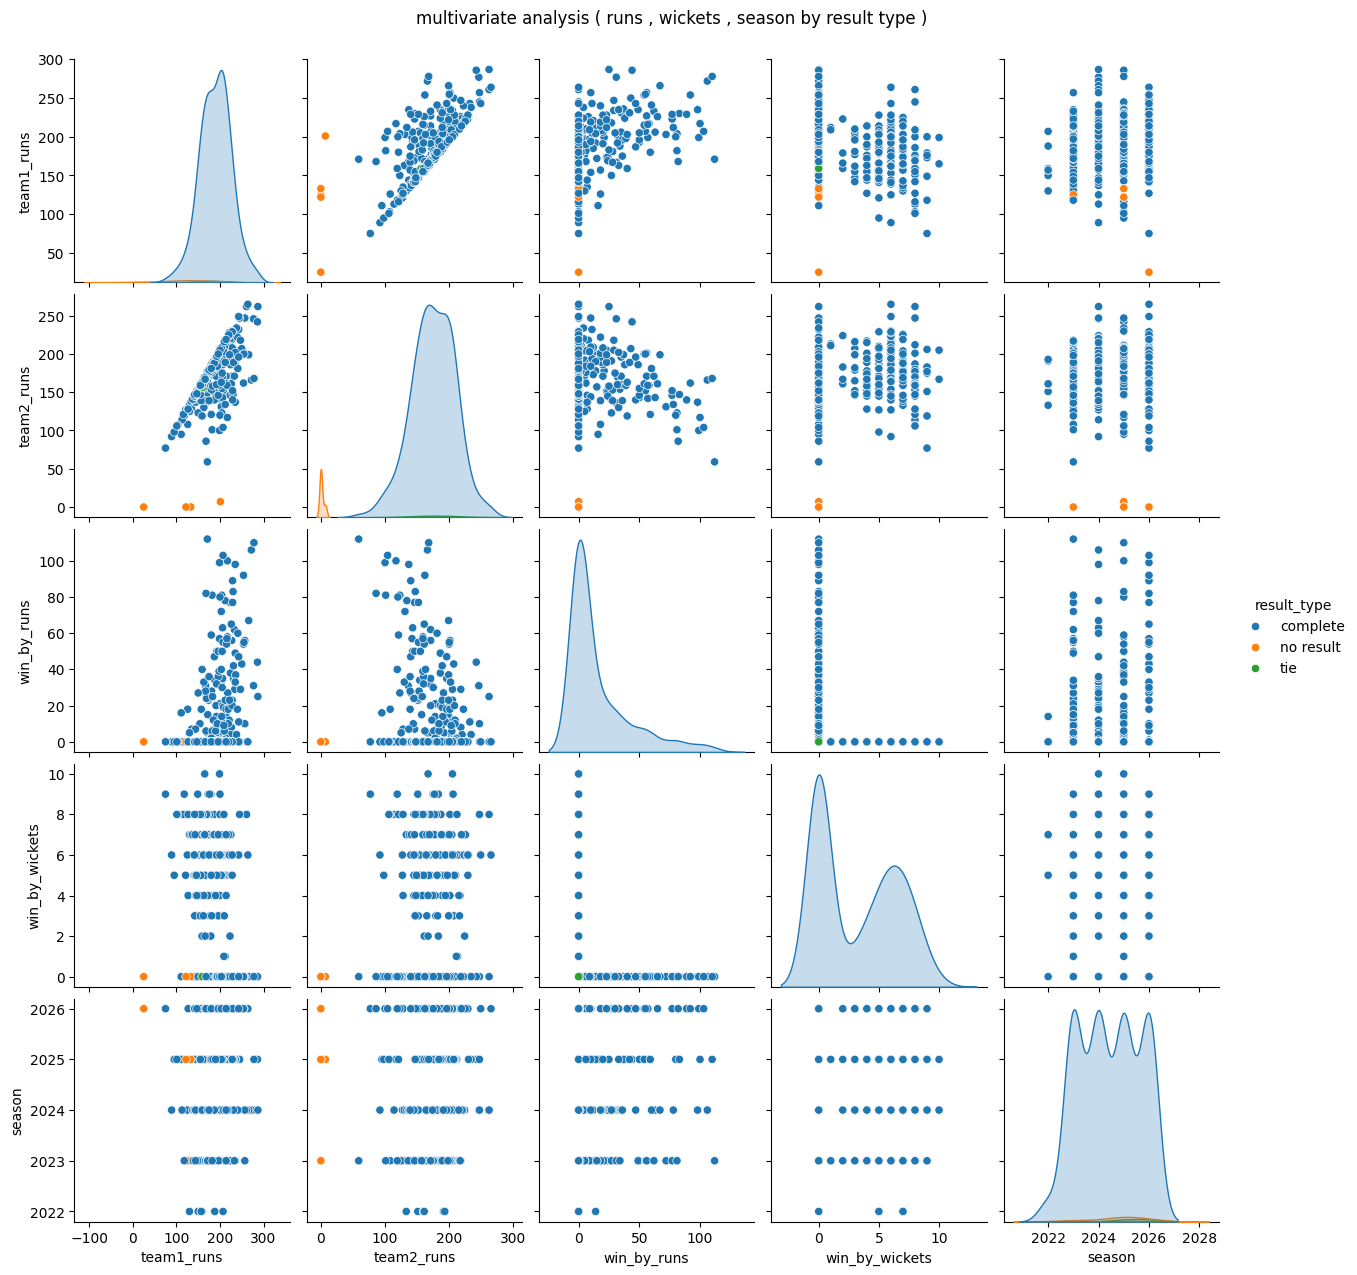

In [76]:
from numpy import diag
# multivariate analysis

cols = ['team1_runs' , 'team2_runs' , 'win_by_runs' , 'win_by_wickets' , 'season' , 'result_type']
multivariate_df = df[cols]

plt.figure(figsize=(8,6))
sns.pairplot(
    multivariate_df ,
    hue = 'result_type' ,
    diag_kind = 'kde'
)
plt.suptitle('multivariate analysis ( runs , wickets , season by result type )' , y = 1.02)
plt.show()

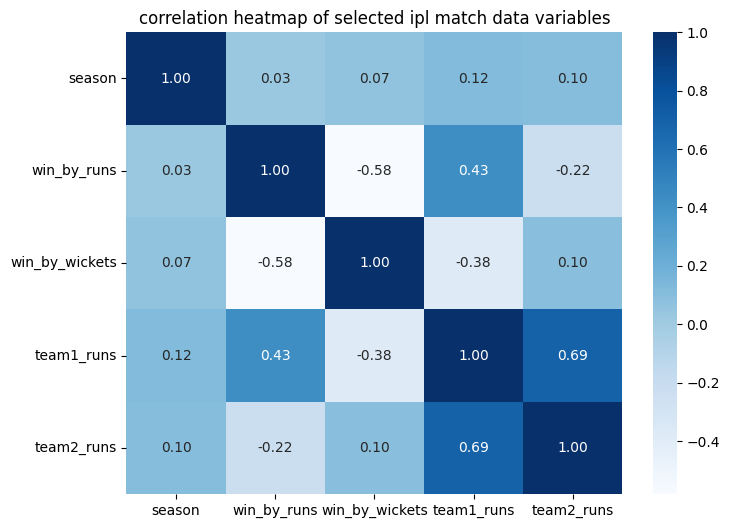

In [81]:
# correlation matrix
numerical_cols = ['season' , 'win_by_runs' , 'win_by_wickets' , 'team1_runs' , 'team2_runs']

corr_df = df[numerical_cols]
corr_matrix = corr_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr_matrix ,
    annot = True ,
    cmap = 'Blues' ,
    fmt = '.2f'
)
plt.title('correlation heatmap of selected ipl match data variables')
plt.show()

# Player analysis

In [82]:
df = pd.read_csv('IPLPlayerStat.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings,player_form,player_form_encoded
0,0,0,A Ashish Reddy,280,31,196,NaN,270,400,28,10.00,142.86,15.82,8.89,22.22,15.00,8,0,Poor,0
1,1,1,A Badoni,161,18,139,2.0,12,12,11,14.64,115.83,12.95,6.00,6.00,6.00,8,0,Average,1
2,2,2,A Chandila,4,0,7,11.0,234,245,12,0.33,57.14,0.00,6.28,22.27,21.27,2,0,Poor,0
3,3,3,A Chopra,53,7,75,0.0,0,0,6,8.83,70.67,9.33,0.00,0.00,0.00,2,0,Poor,0
4,4,4,A Choudhary,25,2,20,5.0,108,144,5,5.00,125.00,10.00,8.00,28.80,21.60,0,0,Poor,0


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 605 entries, 0 to 604
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0.1         605 non-null    int64  
 1   Unnamed: 0           605 non-null    int64  
 2   player               605 non-null    object 
 3   runs                 605 non-null    int64  
 4   boundaries           605 non-null    int64  
 5   balls_faced          605 non-null    int64  
 6   wickets              598 non-null    float64
 7   balls_bowled         605 non-null    int64  
 8   runs_conceded        605 non-null    int64  
 9   matches              605 non-null    int64  
 10  batting_avg          605 non-null    float64
 11  batting_strike_rate  605 non-null    float64
 12  boundaries_percent   605 non-null    float64
 13  bowling_economy      605 non-null    float64
 14  bowling_avg          605 non-null    float64
 15  bowling_strike_rate  605 non-null    flo

In [84]:
# for now lets do mean imputation

mean = df[['wickets']].mean()

print(mean)

wickets    16.600334
dtype: float64


In [85]:
df['wickets'] = df[['wickets']].fillna(mean).astype(int)
df.head()

,Unnamed: 0.1,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings,player_form,player_form_encoded
0,0,0,A Ashish Reddy,280,31,196,16,270,400,28,10.00,142.86,15.82,8.89,22.22,15.00,8,0,Poor,0
1,1,1,A Badoni,161,18,139,2,12,12,11,14.64,115.83,12.95,6.00,6.00,6.00,8,0,Average,1
2,2,2,A Chandila,4,0,7,11,234,245,12,0.33,57.14,0.00,6.28,22.27,21.27,2,0,Poor,0
3,3,3,A Chopra,53,7,75,0,0,0,6,8.83,70.67,9.33,0.00,0.00,0.00,2,0,Poor,0
4,4,4,A Choudhary,25,2,20,5,108,144,5,5.00,125.00,10.00,8.00,28.80,21.60,0,0,Poor,0


In [86]:
most_runs = df.loc[df['runs'].idxmax()]['player']
print(most_runs)

V Kohli


In [87]:
top_5_players_runs = df.sort_values(by='runs', ascending=False).head(5)
display(top_5_players_runs[['player', 'runs']])

,player,runs
569,V Kohli,6634
462,S Dhawan,6244
130,DA Warner,5883
430,RG Sharma,5881
493,SK Raina,5536


In [88]:
most_wickets = df.loc[df['wickets'].idxmax()]['player']
print(most_wickets)

DJ Bravo


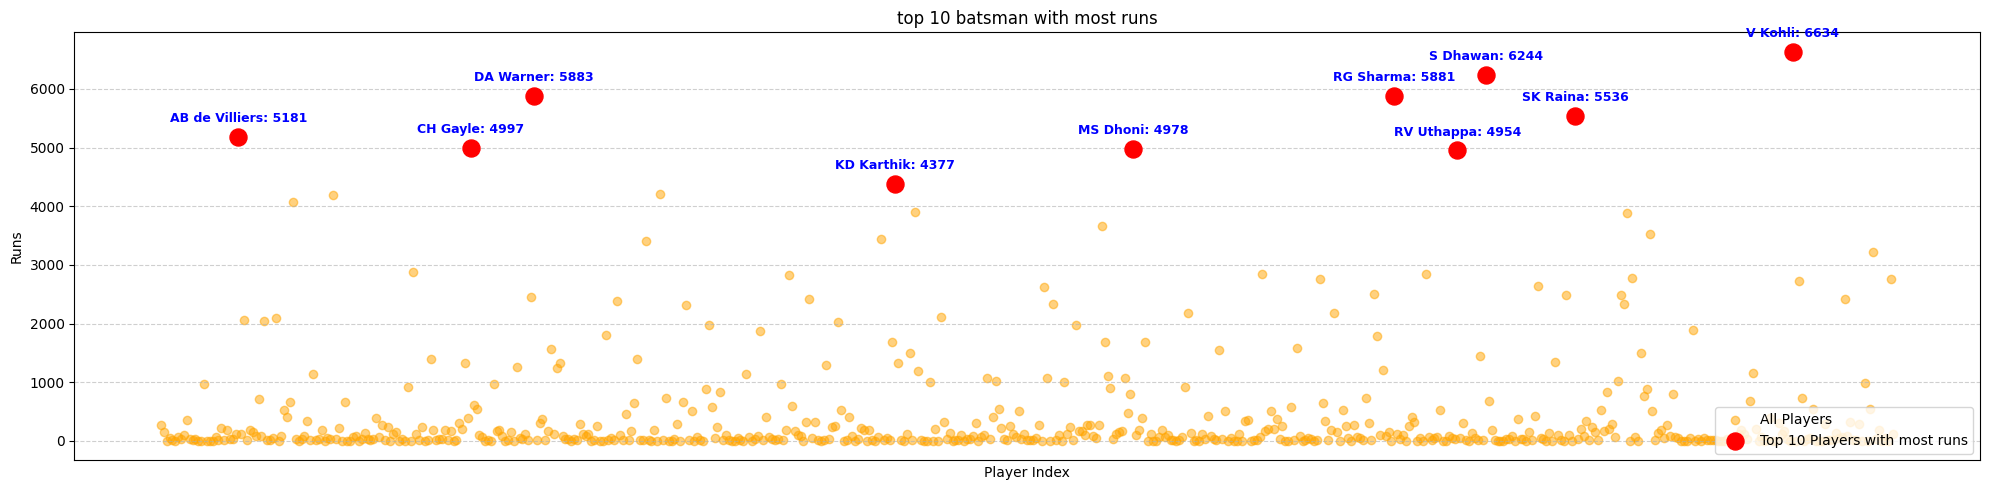

In [89]:
plt.figure(figsize=(20, 5))

# Sort the DataFrame by runs in descending order to get the top players
top10 = df.sort_values(by='runs', ascending=False).head(10)

# Create a scatter plot for all players' runs using their index as x-axis
plt.scatter(df.index, df['runs'], alpha=0.5, label='All Players' , color = 'orange')

# Highlight the top 5 players and annotate them
for index, row in top10.iterrows():
    # Plot the top 5 players
    plt.scatter(index, row['runs'], color='red', s=150, zorder=5, label=f"Top 10 Players with most runs" if index == top10.index[0] else "") # Label only once for the legend
    # Annotate with player name and runs, slightly above the point
    plt.text(index, row['runs'] + 200, f"{row['player']}: {row['runs']}", ha='center', va='bottom', fontsize=9, color='blue', weight='bold')

plt.xlabel('Player Index') # Change xlabel to reflect index
plt.ylabel('Runs')
plt.title('top 10 batsman with most runs')
plt.xticks([]) # Hide x-axis ticks to avoid clutter from all player names
plt.legend(loc='lower right') # Let matplotlib find the best position for the legend
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

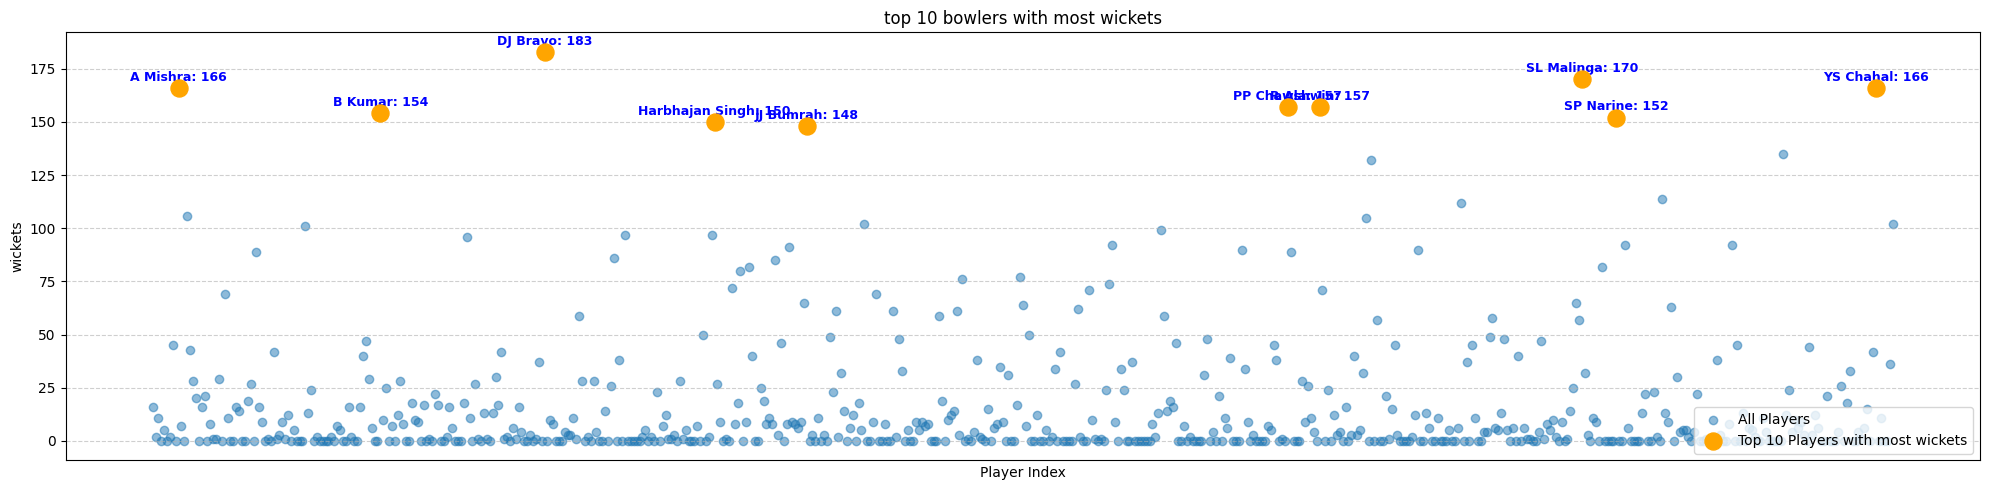

In [90]:
plt.figure(figsize=(20, 5))

# Sort the DataFrame by runs in descending order to get the top players
top10 = df.sort_values(by='wickets', ascending=False).head(10)

# Create a scatter plot for all players' runs using their index as x-axis
plt.scatter(df.index, df['wickets'], alpha=0.5, label='All Players')

# Highlight the top 5 players and annotate them
for index, row in top10.iterrows():
    # Plot the top 10 players
    plt.scatter(index, row['wickets'], color='orange', s=150, zorder=5, label=f"Top 10 Players with most wickets" if index == top10.index[0] else "") # Label only once for the legend
    # Annotate with player name and runs, slightly above the point
    plt.text(index, row['wickets'] + 2 , f"{row['player']}: {row['wickets']}", ha='center', va='bottom', fontsize=9, color='blue', weight='bold')

plt.xlabel('Player Index') # Change xlabel to reflect index
plt.ylabel('wickets')
plt.title('top 10 bowlers with most wickets')
plt.xticks([]) # Hide x-axis ticks to avoid clutter from all player names
plt.legend(loc='lower right') # Let matplotlib find the best position for the legend
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

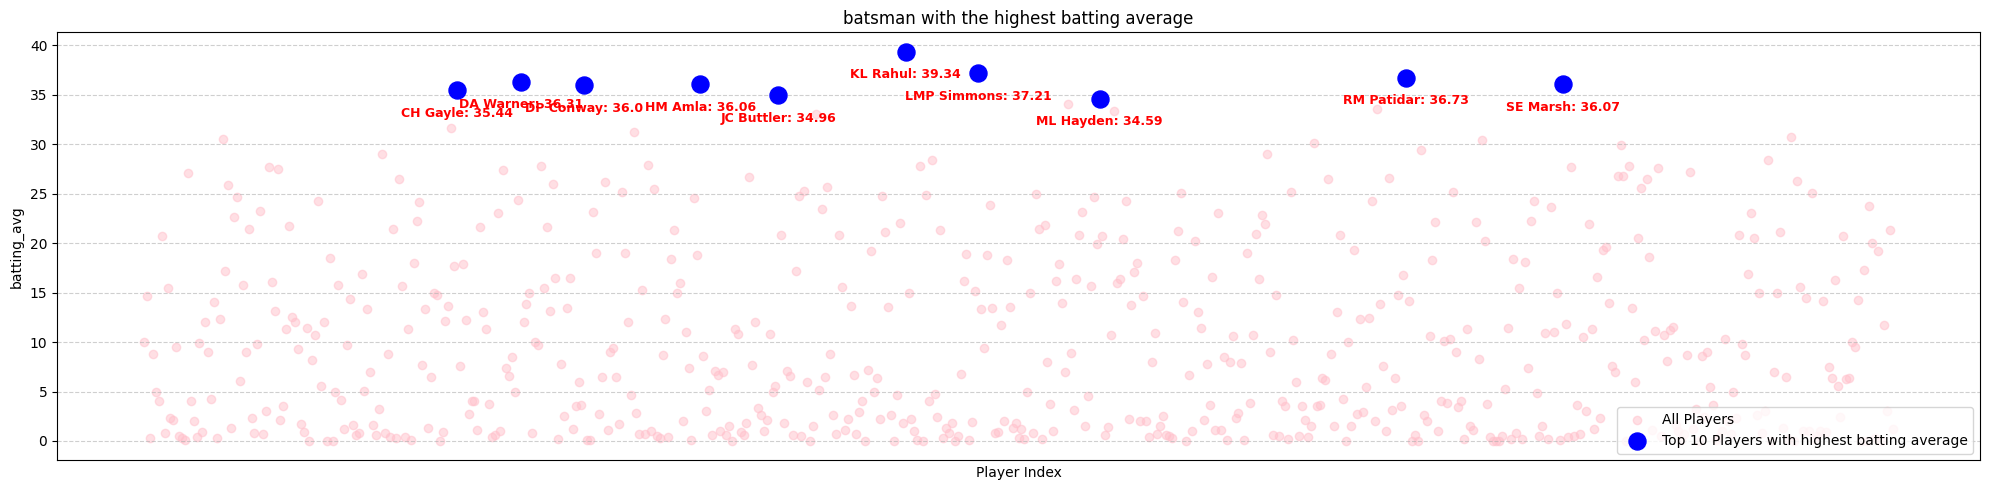

In [91]:
plt.figure(figsize=(20, 5))

# Sort the DataFrame by runs in descending order to get the top players
top10 = df.sort_values(by='batting_avg', ascending=False).head(10)

# Create a scatter plot for all players' runs using their index as x-axis
plt.scatter(df.index, df['batting_avg'], alpha=0.5, label='All Players' , color = 'pink')

# Highlight the top 5 players and annotate them
for index, row in top10.iterrows():
    # Plot the top 5 players
    plt.scatter(index, row['batting_avg'], color='blue', s=150, zorder=5, label=f"Top 10 Players with highest batting average" if index == top10.index[0] else "") # Label only once for the legend
    # Annotate with player name and runs, slightly above the point
    plt.text(index, row['batting_avg'] - 3, f"{row['player']}: {row['batting_avg']}", ha='center', va='bottom', fontsize=9, color='red', weight='bold')

plt.xlabel('Player Index') # Change xlabel to reflect index
plt.ylabel('batting_avg')
plt.title('batsman with the highest batting average')
plt.xticks([]) # Hide x-axis ticks to avoid clutter from all player names
plt.legend(loc='lower right') # Let matplotlib find the best position for the legend
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

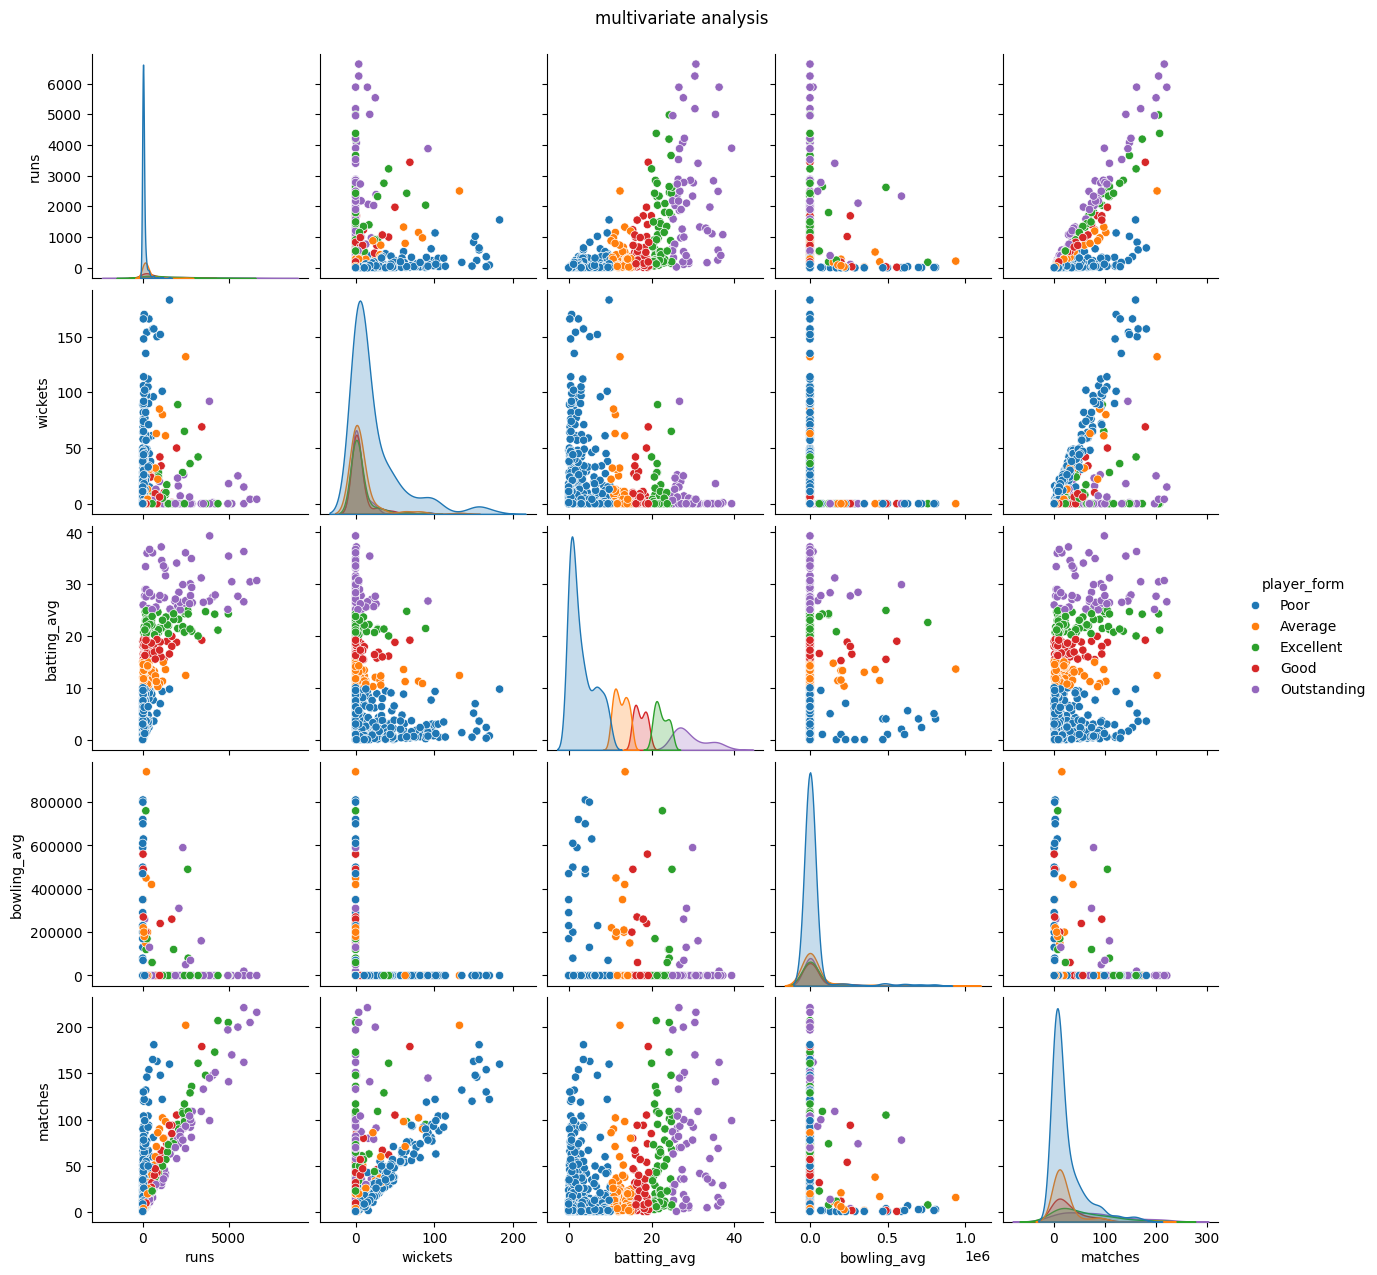

In [92]:
from numpy import diag
# multivariate analysis

cols = ['runs' , 'wickets' , 'batting_avg' , 'bowling_avg' , 'matches', 'player_form']
multivariate_df = df[cols]

plt.figure(figsize=(8,6))
sns.pairplot(
    multivariate_df ,
    hue = 'player_form' ,
    diag_kind = 'kde'
)
plt.suptitle('multivariate analysis' , y = 1.02)
plt.show()

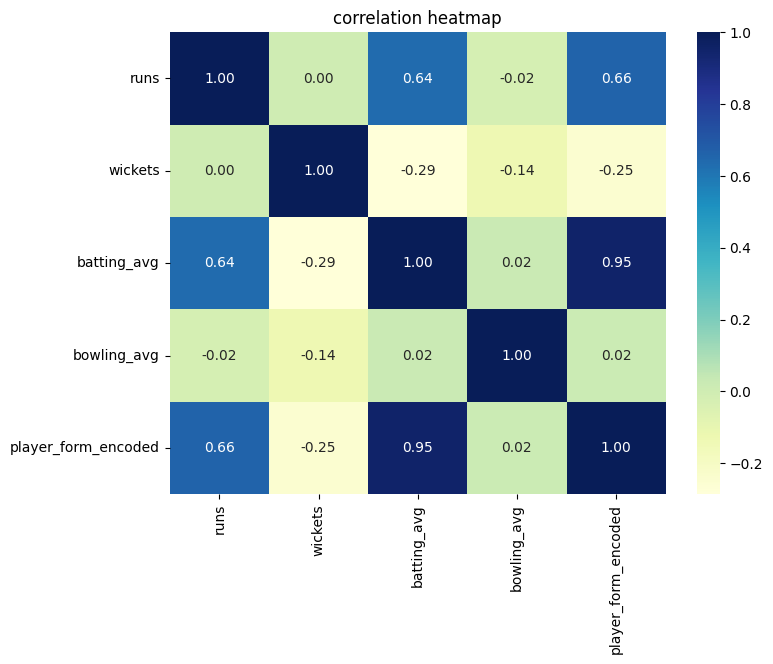

In [93]:
numerical_cols = ['runs' , 'wickets' , 'batting_avg' , 'bowling_avg' , 'player_form_encoded']

corr_df = df[numerical_cols]
corr_matrix = corr_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr_matrix ,
    annot = True ,
    cmap = 'YlGnBu' ,
    fmt = '.2f'
)
plt.title('correlation heatmap')
plt.show()